# Nom des Rapporteurs:
KOUASSI KOUADIO FRANCK

# Importer les bibliothèques

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Lire le fichier CSV

In [19]:
data=pd.read_csv("C:/Users/HP/Desktop/Certificat FORCE-N/DATA/exercice_force_n.csv")

In [20]:
data

,id,age,salaire
0,1,NaN,76301
1,2,18,42280
2,3,120,25402
3,4,NaN,66094
4,5,thirty,78691
...,...,...,...
145,146,120,28889
146,147,40,NaN
147,148,27,1000000
148,149,26,-10000


In [21]:
data.describe()

,id
count,150.000000
mean,75.333333
std,43.394656
min,1.000000
25%,38.250000
50%,75.500000
75%,112.750000
max,150.000000


In [22]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   id       150 non-null    int64 
 1   age      121 non-null    object
 2   salaire  115 non-null    object
dtypes: int64(1), object(2)
memory usage: 3.6+ KB


# Trouver les doublons et Supprimer les doublons

In [23]:
duplicated = data[data.duplicated()]
print("Doublons :\n", duplicated)

data = data.drop_duplicates()


Doublons :
       id     age salaire
11    11  thirty   60835
20    20     NaN   48927
22    22      21     NaN
30    30      48     NaN
43    43      23     NaN
48    48      29  -10000
54    54     120   81415
60    60     NaN   59693
64    64     120   68448
68    68      33  -10000
77    77      31  -10000
84    84      42     NaN
90    90  thirty   51801
96    96      44     NaN
108  108     NaN   52973
120  120      55     NaN
125  125     NaN   79377
127  127     NaN   82309
129  129      29     NaN
132  132      18   92473
135  135      21  fiftyK
138  138      53     NaN
139  138      53     NaN
143  143      37   70691


# Forcer l'âge et le salaire à être des numériques (les erreurs seront transformées en NaN)

In [24]:
data['age'] = pd.to_numeric(data['age'], errors='coerce')
data['salaire'] = pd.to_numeric(data['salaire'], errors='coerce')


C:\Users\HP\AppData\Local\Temp\ipykernel_13972\1197583796.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['age'] = pd.to_numeric(data['age'], errors='coerce')
C:\Users\HP\AppData\Local\Temp\ipykernel_13972\1197583796.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['salaire'] = pd.to_numeric(data['salaire'], errors='coerce')


# Afficher les lignes avec valeurs manquantes
# Option 1 : Supprimer les lignes incomplètes
# Option 2 : Ou remplir par des valeurs statistiques (ex : moyenne)
# df['age'].fillna(df['age'].mean(), inplace=True)
# df['salaire'].fillna(df['salaire'].mean(), inplace=True)

In [25]:

    data['age'].fillna(data['age'].mean(), inplace=True)
    data['salaire'].fillna(data['salaire'].mean(), inplace=True)

C:\Users\HP\AppData\Local\Temp\ipykernel_13972\980606005.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data['age'].fillna(data['age'].mean(), inplace=True)
C:\Users\HP\AppData\Local\Temp\ipykernel_13972\980606005.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['age'].fillna(data['age'].mean(), inplace=True)
C:\Users\HP\AppData\L

# Gérer les valeurs aberrantes
Définissons des limites raisonnables :
âge entre 18 et 65
salaire entre 15 000 et 200 000

In [26]:
data = data[(data['age'] >= 18) & (data['age'] <= 65)]
data = data[(data['salaire'] >= 15000) & (data['salaire'] <= 200000)]


# Exporter les données propres

In [27]:
data.to_csv("individus_nettoyes.csv", index=False)
data

,id,age,salaire
0,1,43.933333,76301.000000
1,2,18.000000,42280.000000
3,4,43.933333,66094.000000
4,5,43.933333,78691.000000
5,6,35.000000,129817.011628
...,...,...,...
140,141,43.933333,51792.000000
142,143,37.000000,70691.000000
144,145,43.933333,56651.000000
146,147,40.000000,129817.011628


# Génération d'un jeu de données fictif pour simuler les salaires

In [28]:
np.random.seed(42)
data = {
    'Age': np.random.randint(22, 60, size=100),
    'Salaire': np.random.normal(loc=45000, scale=12000, size=100).astype(int)
}
df = pd.DataFrame(data)

 # Calculs des mesures de tendance centrale

## la moyenne du salaire des employers 

In [29]:
moyenne_salaire = df['Salaire'].mean()
print("la moyenne est:",moyenne_salaire)

la moyenne est: 46225.44


## la mediane du salaire des employers 

In [30]:
mediane_salaire = df['Salaire'].median()
print("la mediane est:",mediane_salaire)

la mediane est: 45168.5


## le mode du salaire des employers 

In [31]:
mode_salaire = df['Salaire'].mode()[0]
print("la mode est:",mode_salaire)

la mode est: 13137


# Calculs des mesures de dispersion

## Calcul de l'Ecart_type

In [32]:
ecart_type = df['Salaire'].std()
print("l'Ecart_type est:",ecart_type)

l'Ecart_type est: 11711.193274190917


## Calcul de la variance

In [33]:
variance = df['Salaire'].var()
print("la variance est:",variance)

la variance est: 137152047.90545455


## Calcul du salaire entendue

In [34]:
etendue = df['Salaire'].max() - df['Salaire'].min()
print("salaire entendue est:",etendue)

salaire entendue est: 72330


# Histogramme des âges

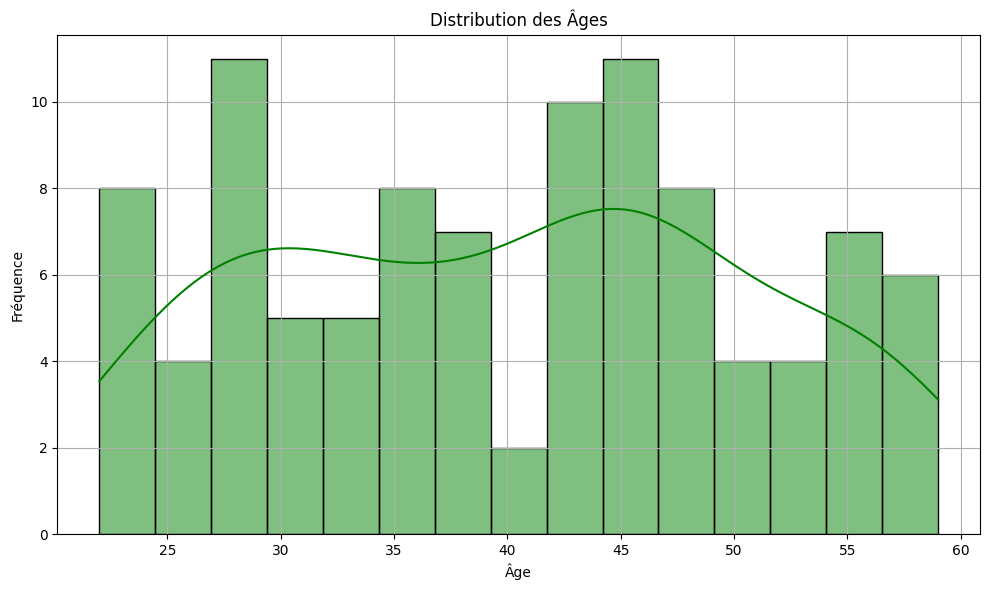

In [35]:
plt.figure(figsize=(10, 6)) # Largeur = 10, Hauteur = 6
sns.histplot(df['Age'], bins=15, kde=True, color='green') 
plt.title('Distribution des Âges')
plt.xlabel('Âge')
plt.ylabel('Fréquence')
plt.grid(True)
plt.tight_layout()
plt.show()

# Histogramme des salaires

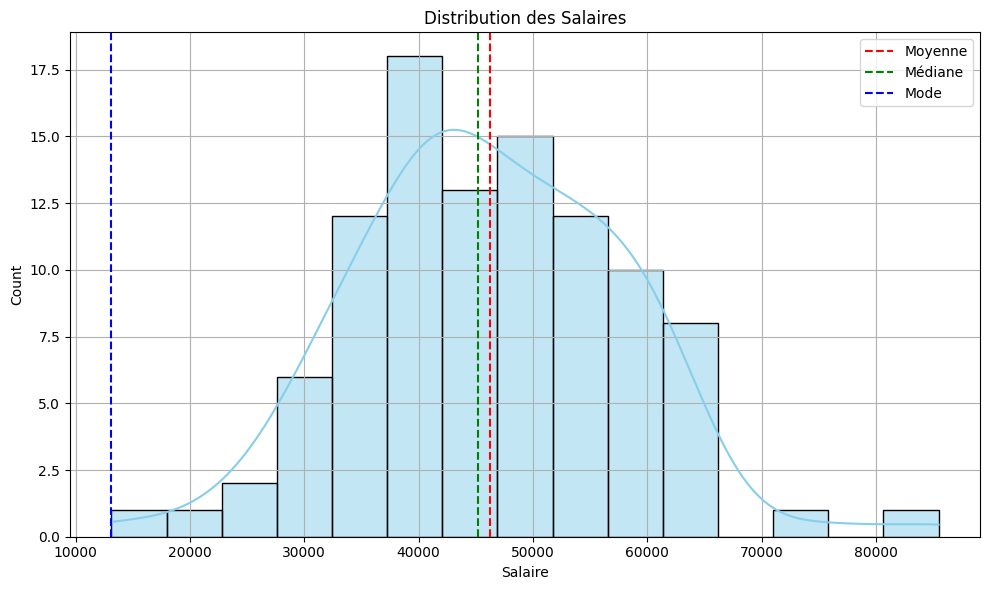

In [36]:

plt.figure(figsize=(10, 6)) # Largeur = 10, Hauteur = 6
sns.histplot(df['Salaire'], kde=True, bins=15, color='skyblue') 
plt.axvline(moyenne_salaire, color='r', linestyle='--', label='Moyenne')
plt.axvline(mediane_salaire, color='g', linestyle='--', label='Médiane')
plt.axvline(mode_salaire, color='b', linestyle='--', label='Mode')
plt.title('Distribution des Salaires')
plt.grid(True)
plt.tight_layout()
plt.legend()

# Boxplots

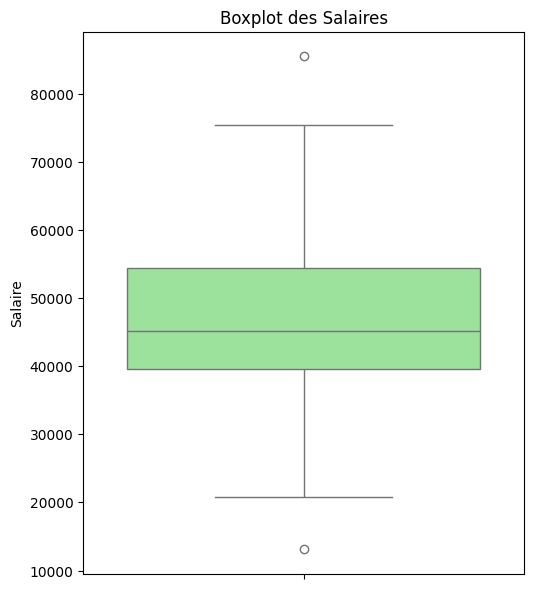

In [37]:
plt.figure(figsize=(10, 6)) # Largeur = 10, Hauteur = 6
plt.subplot(1, 2, 2)
sns.boxplot(y=df['Salaire'], color='lightgreen')
plt.title('Boxplot des Salaires')
plt.tight_layout()
plt.show()

In [38]:
data=pd.DataFrame(data)
print(data.columns)

Index(['Age', 'Salaire'], dtype='object')


# Graphique de dispersion âge vs salaire

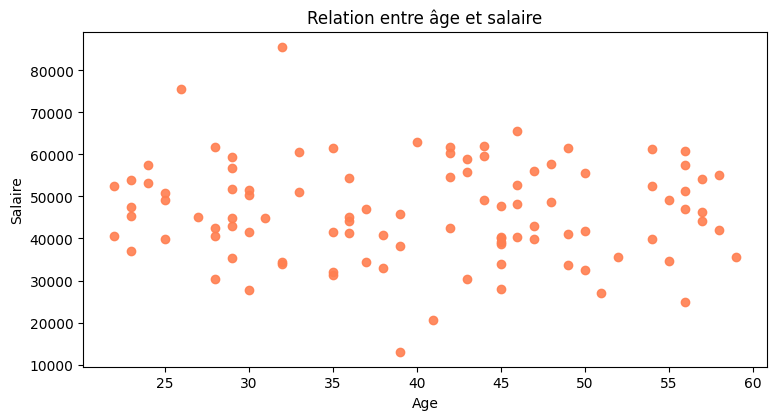

In [39]:
plt.figure(figsize=(30, 20)) # Largeur = 30, Hauteur = 20
plt.subplot(4, 3, 7)
plt.scatter(data['Age'], data['Salaire'], alpha=0.9, color="coral")
plt.xlabel('Age')
plt.ylabel('Salaire')
plt.title('Relation entre âge et salaire')
plt.show()

# Ligne de régression

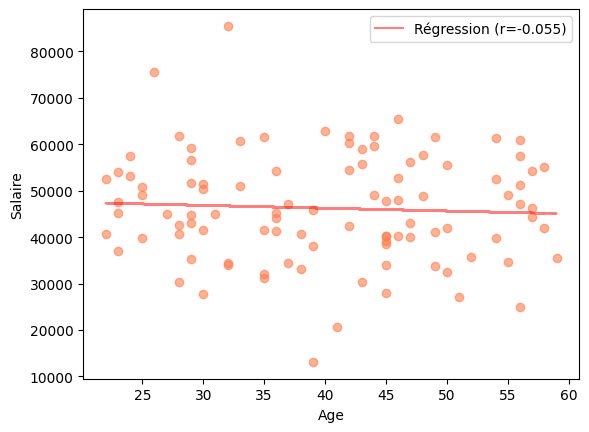

In [40]:

# 1. Calcul de la régression linéaire
p = np.polyfit(data['Age'], data['Salaire'], 1)

# 2. Calcul du coefficient de corrélation (r)
correlation = np.corrcoef(data['Age'], data['Salaire'])[0, 1]

# 3. Tracé de la droite de régression
plt.plot(data['Age'], np.polyval(p, data['Age']), "r", alpha=0.5, 
         label=f'Régression (r={correlation:.3f})')

plt.scatter(data['Age'], data['Salaire'], alpha=0.6, color="coral")
plt.xlabel('Age')
plt.ylabel('Salaire')
plt.legend()
plt.show()

 RAPPORT FINAL DÉTAILLÉ

In [41]:

print("\n" + "="*70)
print("📋 RAPPORT FINAL - ANALYSE COMPLÈTE")
print("="*70)



📋 RAPPORT FINAL - ANALYSE COMPLÈTE
